<a href="https://colab.research.google.com/github/bsheese/387/blob/main/22_images/22_0_Convolution_and_CNNs/22_0_2_First_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Images: Part 2
## A Convolutional Network

---

## What This Notebook Is About

21_1_2 trained the best MLP it could on Fashion-MNIST and got 0.869 on the test images, with shirts and the other upper-body classes as the main source of mistakes. That network saw each image as 784 separate numbers. This notebook replaces it with a **convolutional neural network** (CNN) built from the layers in 22_0_1, trains it with the same recipe on the same images, and compares the two.

**What you will learn:**
1. How a CNN is put together, and how to follow the shape of the data through it
2. How much better it does than the MLP, and on which classes
3. What its first layer's filters learned
4. Why a CNN copes with an image that's been shifted by a couple of pixels, and an MLP doesn't
5. What **batch normalization** does during training
6. **Data augmentation**: making extra training images by changing the ones you have

This notebook trains several networks. On Colab's GPU (Runtime → Change runtime type → T4 GPU) each takes seconds; on a CPU the longest takes a few minutes. The notebook is saved with its outputs, so you can read the results before running anything.

In [1]:
import os
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torchvision.transforms import v2

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

DATA_URL = 'https://raw.githubusercontent.com/bsheese/387/main/data/'

def fetch(name):
    # Download a file from the course's data folder, unless it is already here.
    if not os.path.exists(name):
        urllib.request.urlretrieve(DATA_URL + name, name)
    return name

data = np.load(fetch('fashion10k.npz'))
CLASSES = list(data['classes'])

def prepare(images, labels):
    # keep the image shape this time: (number of images, 1 channel, 28, 28), values 0 to 1
    X = torch.tensor(images[:, None] / 255, dtype=torch.float32)
    return X.to(device), torch.tensor(labels, dtype=torch.long).to(device)

X_train, y_train = prepare(data['x_train'], data['y_train'])
X_val, y_val = prepare(data['x_val'], data['y_val'])
X_test, y_test = prepare(data['x_test'], data['y_test'])
print('X_train:', X_train.shape)

device: cpu
X_train: torch.Size([10000, 1, 28, 28])


The only change from unit 21's `prepare` is that the images keep their shape, with a channel dimension of 1 for grayscale, instead of being flattened.

The training functions are 21_1_2's, with one addition used in Section 6: `train_one_epoch` can take an `augment` function that changes each training image before the network sees it.

In [2]:
loss_fn = nn.CrossEntropyLoss()

def train_one_epoch(model, loader, optimizer, augment=None):
    model.train()
    for x, y in loader:
        if augment is not None:
            x = torch.stack([augment(img) for img in x])     # a different random change for every image
        optimizer.zero_grad()
        loss = loss_fn(model(x), y)
        loss.backward()
        optimizer.step()

def evaluate(model, X, y):
    model.eval()
    with torch.no_grad():
        scores = model(X)
        return loss_fn(scores, y).item(), (scores.argmax(dim=1) == y).float().mean().item()

def fit(model, epochs, X=None, y=None, augment=None, lr=0.001, weight_decay=0.05, schedule=True):
    # 21_1_2's recipe: AdamW, a cosine schedule, and a checkpoint of the best validation loss
    X = X_train if X is None else X
    y = y_train if y is None else y
    loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X, y), batch_size=64, shuffle=True)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs) if schedule else None
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    best_loss, best_state = float('inf'), None
    for epoch in range(epochs):
        train_one_epoch(model, loader, optimizer, augment)
        if scheduler is not None:
            scheduler.step()
        for name, Xs, ys in [('train', X, y), ('val', X_val, y_val)]:
            loss, acc = evaluate(model, Xs, ys)
            history[f'{name}_loss'].append(loss)
            history[f'{name}_acc'].append(acc)
        if history['val_loss'][-1] < best_loss:
            best_loss = history['val_loss'][-1]
            best_state = {k: v.clone() for k, v in model.state_dict().items()}   # a checkpoint kept in memory
    model.load_state_dict(best_state)
    return history

(This `fit` keeps its checkpoint in memory, with `.clone()` copying every tensor, instead of writing it to a file. It trains for the full number of epochs and then restores the best one. `schedule=False` turns off the cosine schedule, which Section 6 uses.)

---

## Section 1: The Network, Layer by Layer

The CNN has two convolutional **blocks**. Each block is a 3 × 3 convolution with padding 1 (so the size doesn't change), batch normalization (Section 5), ReLU, and 2 × 2 max pooling (so the size halves). After the blocks, the feature maps are flattened and passed to the same kind of layers as the MLP: a hidden `nn.Linear` layer with dropout, and an output layer with 10 scores.

In [3]:
def make_cnn(batch_norm=True):
    def block(c_in, c_out):
        return [nn.Conv2d(c_in, c_out, kernel_size=3, padding=1),
                nn.BatchNorm2d(c_out) if batch_norm else nn.Identity(),
                nn.ReLU(),
                nn.MaxPool2d(2)]
    return nn.Sequential(
        *block(1, 32),               # 1 x 28 x 28  ->  32 x 14 x 14
        *block(32, 64),              # 32 x 14 x 14 ->  64 x 7 x 7
        nn.Flatten(),                # 64 x 7 x 7   ->  3,136 numbers
        nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Dropout(0.3),
        nn.Linear(128, 10),
    ).to(device)

cnn = make_cnn()
x = X_train[:5]
print(f'{"input":36} {tuple(x.shape)}')
for layer in cnn:
    x = layer(x)
    print(f'{str(layer)[:36]:36} {tuple(x.shape)}')

input                                (5, 1, 28, 28)
Conv2d(1, 32, kernel_size=(3, 3), st (5, 32, 28, 28)
BatchNorm2d(32, eps=1e-05, momentum= (5, 32, 28, 28)
ReLU()                               (5, 32, 28, 28)
MaxPool2d(kernel_size=2, stride=2, p (5, 32, 14, 14)
Conv2d(32, 64, kernel_size=(3, 3), s (5, 64, 14, 14)
BatchNorm2d(64, eps=1e-05, momentum= (5, 64, 14, 14)
ReLU()                               (5, 64, 14, 14)
MaxPool2d(kernel_size=2, stride=2, p (5, 64, 7, 7)
Flatten(start_dim=1, end_dim=-1)     (5, 3136)
Linear(in_features=3136, out_feature (5, 128)
ReLU()                               (5, 128)
Dropout(p=0.3, inplace=False)        (5, 128)
Linear(in_features=128, out_features (5, 10)


Passing a small batch through one layer at a time and printing the shape is the most useful habit for building CNNs. You can see the image shrink (28 → 14 → 7) while the number of channels grows (1 → 32 → 64), and `nn.Flatten` turns each image's 64 × 7 × 7 feature maps into one row of 3,136 numbers for the `nn.Linear` layer. If the 3,136 in `nn.Linear(64 * 7 * 7, 128)` were wrong, this is where the shape error would appear.

The `*` in `*block(1, 32)` unpacks the list of four layers that `block` returns, so that `nn.Sequential` gets them as separate layers.

In [4]:
count = lambda model: sum(p.numel() for p in model.parameters())
print(f'CNN: {count(cnn):,} weights')
for name, p in cnn.named_parameters():
    if p.ndim > 1:
        print(f'   {name:10} {str(list(p.shape)):18} {p.numel():>9,}')
print(f'21_1_2 MLP: {784 * 512 + 512 + 512 * 512 + 512 + 512 * 10 + 10:,} weights')

CNN: 421,834 weights
   0.weight   [32, 1, 3, 3]            288
   4.weight   [64, 32, 3, 3]        18,432
   9.weight   [128, 3136]          401,408
   12.weight  [10, 128]              1,280
21_1_2 MLP: 669,706 weights


The CNN has fewer weights than the MLP, and almost all of them are in the first `nn.Linear` layer. The two convolutional layers together have under 20,000.

---

## Section 2: Training the CNN

Same images, same recipe as 21_1_2 (AdamW with weight decay 0.05, a cosine schedule, the checkpoint with the lowest validation loss), 12 epochs:

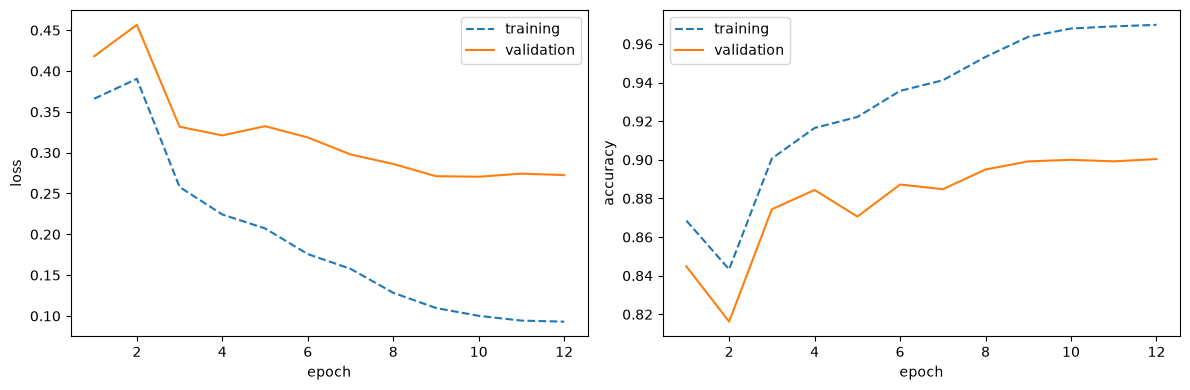

CNN test accuracy: 0.897   (21_1_2 MLP: 0.869)


In [5]:
torch.manual_seed(0)
cnn = make_cnn()
cnn_history = fit(cnn, epochs=12)

epochs = range(1, 13)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(epochs, cnn_history['train_loss'], '--', label='training'); ax1.plot(epochs, cnn_history['val_loss'], label='validation')
ax2.plot(epochs, cnn_history['train_acc'], '--', label='training'); ax2.plot(epochs, cnn_history['val_acc'], label='validation')
ax1.set_ylabel('loss'); ax2.set_ylabel('accuracy')
for ax in (ax1, ax2):
    ax.set_xlabel('epoch'); ax.legend()
plt.tight_layout(); plt.show()

cnn_test_loss, cnn_test_acc = evaluate(cnn, X_test, y_test)
print(f'CNN test accuracy: {cnn_test_acc:.3f}   (21_1_2 MLP: 0.869)')

The CNN gets a clearly higher test accuracy than the best MLP, with fewer weights and fewer epochs. Its validation loss also ends well below the MLP's best (0.374 in 21_1_2).

Which classes improved? The next cell trains 21_1_2's MLP again with the same recipe (it takes a few seconds) so the two can be compared class by class. We need the MLP itself again in Section 4 anyway.

In [6]:
torch.manual_seed(0)
mlp = nn.Sequential(
    nn.Flatten(),                     # the MLP flattens the images itself
    nn.Linear(784, 512), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(512, 512), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(512, 10),
).to(device)
fit(mlp, epochs=30)
mlp_test_acc = evaluate(mlp, X_test, y_test)[1]
print(f'MLP test accuracy: {mlp_test_acc:.3f}')

def per_class(model):
    with torch.no_grad():
        predicted = model(X_test).argmax(dim=1)
    return [(predicted[y_test == k] == k).float().mean().item() for k in range(10)]

print(f"\n{'':12} {'MLP':>6} {'CNN':>6}")
for k, (m, c) in enumerate(zip(per_class(mlp), per_class(cnn))):
    print(f'{CLASSES[k]:12} {m:6.2f} {c:6.2f} {c - m:+6.2f}')

MLP test accuracy: 0.869

                MLP    CNN


T-shirt/top    0.82   0.87  +0.05
Trouser        0.97   0.98  +0.01
Pullover       0.82   0.83  +0.01
Dress          0.88   0.90  +0.02
Coat           0.77   0.86  +0.09
Sandal         0.94   0.98  +0.03
Shirt          0.62   0.67  +0.04
Sneaker        0.94   0.94  +0.01
Bag            0.96   0.98  +0.02
Ankle boot     0.95   0.97  +0.01


The biggest gains are for coats, T-shirts and shirts, three of the upper-body classes the MLP found hardest, where details of shape like a collar, buttons or the cut of the sleeves are what tell them apart. (Pullovers barely changed.) Shirts are still the hardest class: at 28 × 28 pixels some shirts really do look like T-shirts or pullovers.

---

## Section 3: What the First Layer Learned

The first convolutional layer has 32 filters of 3 × 3 weights, learned from the data. Here they are, with each filter's weights shown as a tiny image (red for positive weights, blue for negative), followed by the 32 feature maps they produce for one test image:

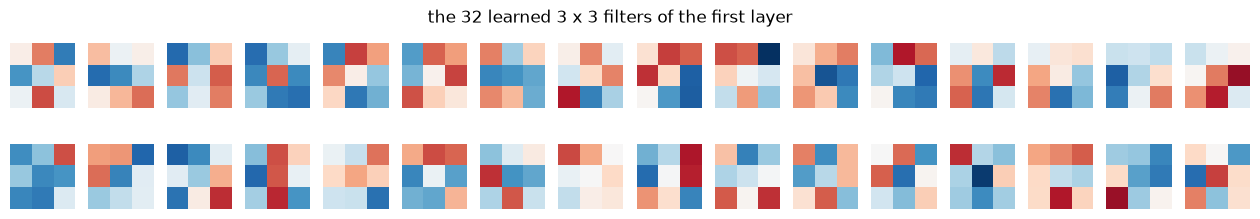

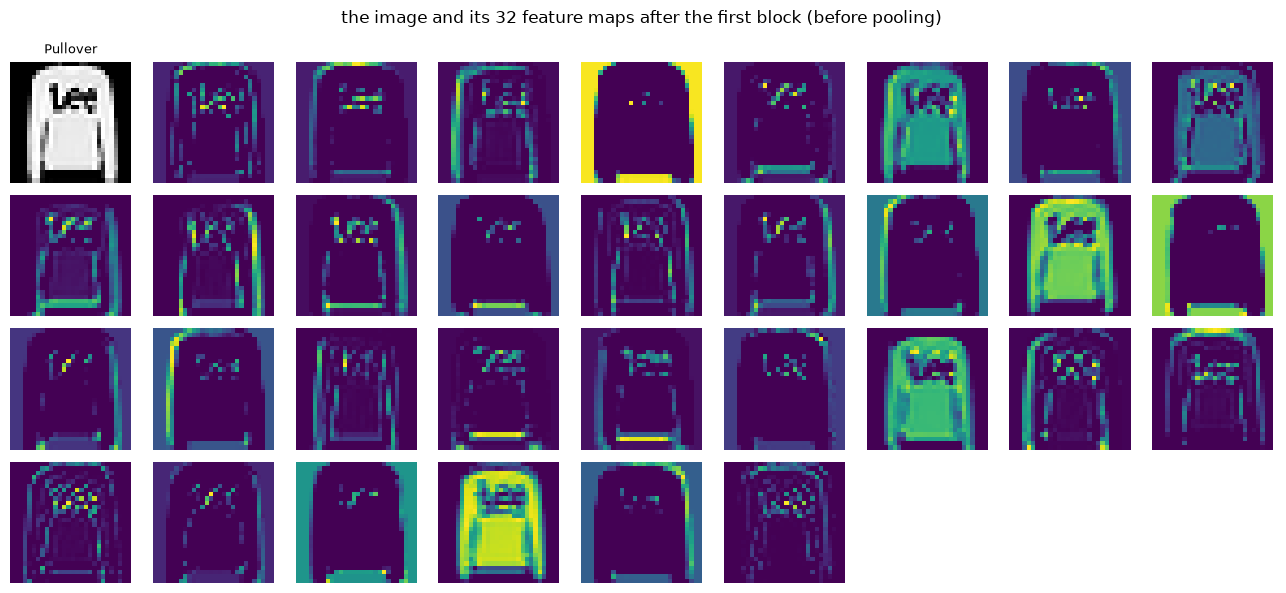

In [7]:
weights = cnn[0].weight.detach().cpu()[:, 0]          # (32, 3, 3)
fig, axes = plt.subplots(2, 16, figsize=(16, 2.4))
for ax, w in zip(axes.flat, weights):
    ax.imshow(w, cmap='RdBu_r', vmin=-weights.abs().max(), vmax=weights.abs().max())
    ax.axis('off')
plt.suptitle('the 32 learned 3 x 3 filters of the first layer')
plt.show()

image = X_test[1:2]
with torch.no_grad():
    maps = cnn[2](cnn[1](cnn[0](image)))[0].cpu()      # conv, batch norm, ReLU
fig, axes = plt.subplots(4, 9, figsize=(13, 6))
axes[0, 0].imshow(image[0, 0].cpu(), cmap='gray')
axes[0, 0].set_title(CLASSES[y_test[1]], fontsize=9)
for ax, fm in zip(list(axes.flat)[1:], maps):
    ax.imshow(fm, cmap='viridis')
for ax in axes.flat:
    ax.axis('off')
plt.suptitle('the image and its 32 feature maps after the first block (before pooling)')
plt.tight_layout()
plt.show()

Many of the learned filters have a positive side and a negative side, like the hand-made edge detectors in 22_0_1, at various angles. Their feature maps light up along different parts of the outline: some on left edges, some on top edges, some on the inside or the background. Nobody designed these filters. They're what gradient descent found useful for telling clothes apart. The second layer combines them into features that cover larger areas, which are much harder to show as pictures.

---

## Section 4: Shifting the Images

22_0_1 argued that a filter used at every position will find a pattern wherever it appears. Here's a direct test. Shift every test image a few pixels to the right (filling in black on the left) and measure both networks again. Neither network saw shifted images during training.

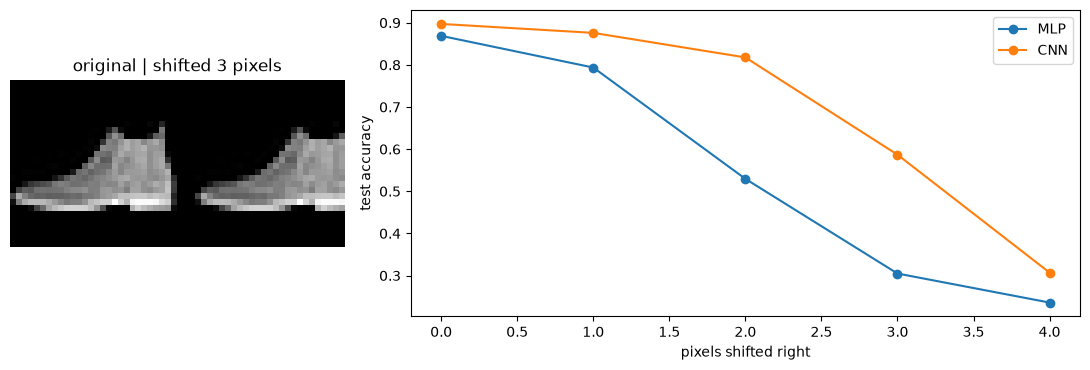

MLP [0.869, 0.794, 0.53, 0.305, 0.236]
CNN [0.897, 0.876, 0.818, 0.587, 0.307]


In [8]:
def shift_right(X, pixels):
    shifted = torch.roll(X, shifts=pixels, dims=3)     # dims=3 is the width
    shifted[..., :pixels] = 0                           # blank the columns that wrapped around
    return shifted

shifts = [0, 1, 2, 3, 4]
results = {'MLP': [], 'CNN': []}
for s in shifts:
    Xs = shift_right(X_test, s) if s > 0 else X_test
    results['MLP'].append(evaluate(mlp, Xs, y_test)[1])
    results['CNN'].append(evaluate(cnn, Xs, y_test)[1])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={'width_ratios': [1, 2]})
axes[0].imshow(torch.cat([X_test[0, 0], shift_right(X_test[:1], 3)[0, 0]], dim=1).cpu(), cmap='gray')
axes[0].set_title('original | shifted 3 pixels'); axes[0].axis('off')
for name, accs in results.items():
    axes[1].plot(shifts, accs, marker='o', label=name)
axes[1].set_xlabel('pixels shifted right'); axes[1].set_ylabel('test accuracy'); axes[1].legend()
plt.tight_layout(); plt.show()
for name, accs in results.items():
    print(name, [round(a, 3) for a in accs])

A shift of 1 or 2 pixels is barely noticeable to a person. The MLP's accuracy falls a long way even at 2 pixels: every one of its inputs is tied to one pixel position, so after a shift each input carries a different part of the image, and the weights it learned no longer line up. The CNN loses much less at 1 or 2 pixels, because its filters respond to the same edges at their new positions and pooling absorbs part of the change. By 3 or 4 pixels the CNN is falling too. Its `nn.Linear` layer gives each position in the final 7 × 7 grid its own weights, so once features move into different grid cells, it's in the same position as the MLP. Networks that end with global average pooling, such as ResNet-18 in 22_1_1, depend much less on where features are.

---

## Section 5: Batch Normalization

The CNN has a batch-norm layer after each convolution. During training, **batch normalization** takes each channel's values across the current batch and rescales them to an average of 0 and a standard deviation of 1. It's the standardizing from 20_0_3, done inside the network, at every step. Then it multiplies by a learned scale and adds a learned shift, so the layer can still pass on whatever range of values works best. It also keeps a running average of the means and standard deviations it has seen, which it uses in evaluation mode (21_1_1).

Without it, the range of values reaching each layer drifts as the weights of the layers before it change, and each layer has to keep adjusting to that. With it, every layer receives values on a steady scale, which usually lets the network train faster and with less sensitivity to the learning rate.

Here are two CNNs, identical except for batch norm, trained for 5 epochs:

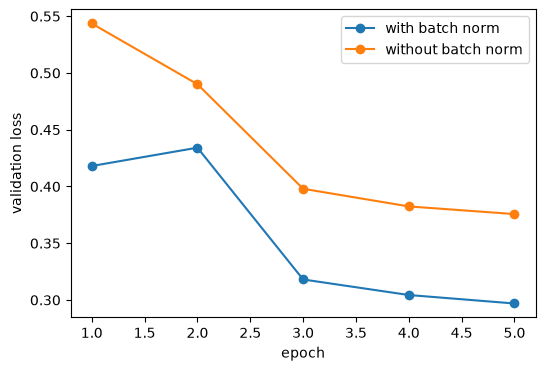

with batch norm      validation loss after each epoch: [0.418, 0.434, 0.318, 0.304, 0.297]
without batch norm   validation loss after each epoch: [0.544, 0.49, 0.398, 0.382, 0.376]


In [9]:
bn_histories = {}
for label, use_bn in [('with batch norm', True), ('without batch norm', False)]:
    torch.manual_seed(0)
    bn_histories[label] = fit(make_cnn(batch_norm=use_bn), epochs=5)

plt.figure(figsize=(6, 4))
for label, h in bn_histories.items():
    plt.plot(range(1, 6), h['val_loss'], marker='o', label=label)
plt.xlabel('epoch'); plt.ylabel('validation loss'); plt.legend(); plt.show()
for label, h in bn_histories.items():
    print(f"{label:20} validation loss after each epoch: {[round(v, 3) for v in h['val_loss']]}")

With batch norm, the validation loss is lower from the first epoch on. On a network this small the difference is real but modest, and both networks get there eventually. In deep networks such as ResNet-18, with dozens of layers, batch norm makes a much bigger difference, and it's one of the things that made training networks that deep practical.

---

## Section 6: Data Augmentation

21_1_1 found that more training images helped more than any regularization technique. **Data augmentation** makes more training images out of the ones you have, by changing each image randomly every time the network sees it, in ways that don't change its label. For clothing photos, two safe changes are:

- shifting the image by up to 10% in any direction (Section 4 showed that shifts matter)
- flipping it left to right (a mirrored shirt is still a shirt)

Turning it upside down would *not* be safe: that produces images unlike any real test image. Choosing augmentations means asking what changes the real data could plausibly have.

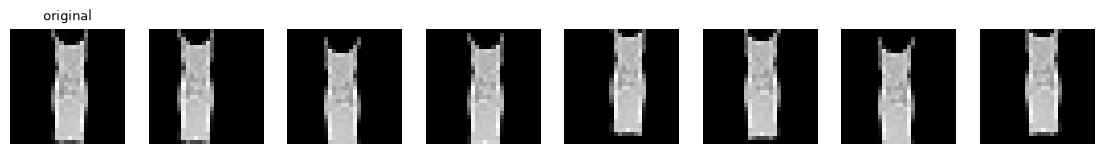

In [10]:
augment = v2.Compose([
    v2.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    v2.RandomHorizontalFlip(),
])

example = X_train[3]
fig, axes = plt.subplots(1, 8, figsize=(14, 2))
axes[0].imshow(example[0].cpu(), cmap='gray'); axes[0].set_title('original', fontsize=9)
for ax in axes[1:]:
    ax.imshow(augment(example)[0].cpu(), cmap='gray')
for ax in axes:
    ax.axis('off')
plt.show()

Every epoch the network sees a slightly different version of each training image, so it can't memorize exact pixels. To make the effect easy to see, we go back to 21_1_1's setting: 1,000 training images, where overfitting is a real problem, trained for 30 epochs with and without augmentation, and with a constant learning rate as in 21_1_1. (The cosine schedule also reduces late overfitting, which would make the comparison harder to read.)

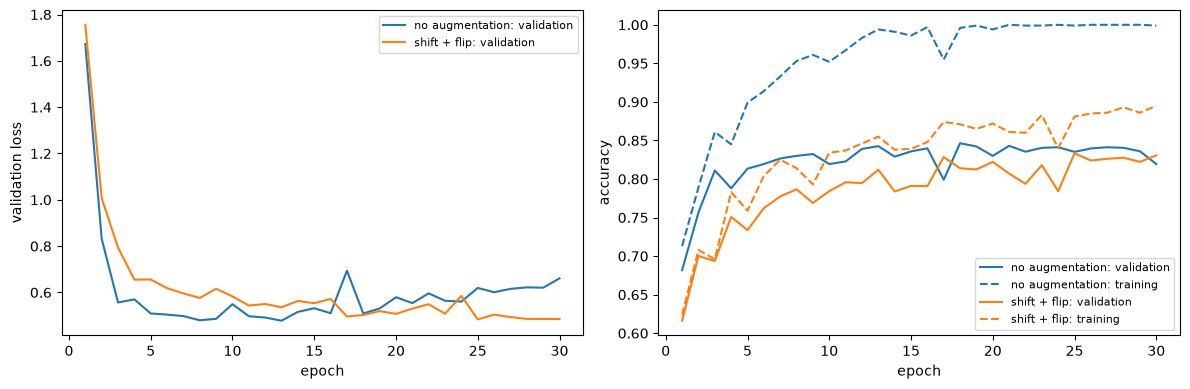

no augmentation  final training acc 0.999   best validation acc 0.846   final validation loss 0.661
shift + flip     final training acc 0.895   best validation acc 0.833   final validation loss 0.485


In [11]:
small = torch.cat([torch.where(y_train == k)[0][:100] for k in range(10)])
aug_histories = {}
for label, aug in [('no augmentation', None), ('shift + flip', augment)]:
    torch.manual_seed(0)
    aug_histories[label] = fit(make_cnn(), epochs=30, X=X_train[small], y=y_train[small], augment=aug, schedule=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for label, h in aug_histories.items():
    line, = ax1.plot(range(1, 31), h['val_loss'], label=f'{label}: validation')
    ax2.plot(range(1, 31), h['val_acc'], color=line.get_color(), label=f'{label}: validation')
    ax2.plot(range(1, 31), h['train_acc'], '--', color=line.get_color(), label=f'{label}: training')
ax1.set_ylabel('validation loss'); ax2.set_ylabel('accuracy')
for ax in (ax1, ax2):
    ax.set_xlabel('epoch'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
for label, h in aug_histories.items():
    print(f"{label:16} final training acc {h['train_acc'][-1]:.3f}   best validation acc {max(h['val_acc']):.3f}   "
          f"final validation loss {h['val_loss'][-1]:.3f}")

Without augmentation, the network reaches perfect accuracy on its 1,000 training images and its validation loss climbs, the overfitting pattern from 21_1_1. With augmentation, it can't memorize the training images (its training accuracy stays below 1.0), and its validation loss stays much lower. The best validation accuracy is about the same in both runs here, a little lower with augmentation; augmented training usually needs more epochs to catch up, since every epoch shows it harder versions of the images. As with dropout in 21_1_1, the clearest effect is that the network stops becoming overconfident about its mistakes; augmentation is not a substitute for real new images, but it's free, and it's standard practice for training image models. 22_1_1 uses it when fine-tuning on the Pets photos.

---

## Summary

- A **CNN** stacks convolutional blocks (convolution, batch norm, ReLU, max pooling) that shrink the image and add channels, then flattens the feature maps for `nn.Linear` layers. Printing the shape after each layer shows where the data goes and catches shape errors.
- On the same Fashion-MNIST images and with the same recipe, the CNN beats 21_1_2's MLP (0.869) with fewer weights, and gains most on the upper-body classes.
- Its first-layer filters, learned from data, look like edge detectors at different angles.
- Shifting test images by a few pixels hurts the MLP badly and the CNN much less, because convolution uses the same filter at every position and pooling absorbs small changes in position.
- **Batch normalization** rescales each channel's values within a batch during training, which keeps every layer's inputs on a steady scale and speeds up training. In evaluation it uses running averages (21_1_1).
- **Data augmentation** changes training images randomly in ways that keep their labels (here shifts and flips). With 1,000 images it stopped the network memorizing and kept the validation loss down.

**Next:** 22_1_1 goes back to the Pets model from 19_0 and opens it up: ResNet-18 is a much deeper CNN, trained on ImageNet, and reusing its layers is what made 19_0 work with 400 photos.